# 🌳 Notebook 4 — Long-Chain Branching (Coordination Polymerization)
| | |
|---|---|
| ⏱ Time | ~35 min |
| 🧭 Type | **steady state Monte Carlo** (book Ch. 3, Case Study 3.3) |
| 🎯 You will learn | keep a **pool** of molecules that can react again · count branches · classify linear / comb / hyperbranched molecules |
| 🧰 Uses | Notebook 2's growth loop, plus a list of "macromonomers" |

**The chemistry in one picture:** a catalyst makes a chain. When the chain ends by **β-hydride elimination**, it keeps a vinyl end and becomes a **macromonomer**. A later growing chain can grab that whole macromonomer: a **long-chain branch (LCB)**. Kinetics: *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

random.seed(11)

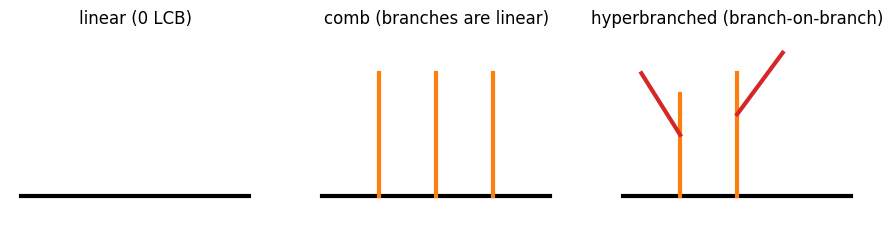

In [2]:
#@title Draw the three architectures
fig, ax = plt.subplots(1, 3, figsize=(11, 2.4))
def line(a, x0, y0, x1, y1, c="k"): a.plot([x0, x1], [y0, y1], c=c, lw=3)
line(ax[0], 0, 0, 10, 0)
line(ax[1], 0, 0, 10, 0)
for xb in (2.5, 5, 7.5): line(ax[1], xb, 0, xb, 3, "tab:orange")
line(ax[2], 0, 0, 10, 0); line(ax[2], 5, 0, 5, 3, "tab:orange"); line(ax[2], 5, 2, 7, 3.5, "tab:red")
line(ax[2], 2.5, 0, 2.5, 2.5, "tab:orange"); line(ax[2], 2.5, 1.5, 0.8, 3, "tab:red")
for a, t in zip(ax, ["linear (0 LCB)", "comb (branches are linear)", "hyperbranched (branch-on-branch)"]):
    a.set_title(t); a.axis("off"); a.set_ylim(-0.5, 4)
plt.show()

## 1 · The macromonomer pool
The **pool** is a list with the numbers (indices) of the chains that are macromonomers. When a growing chain needs one, it picks one at random and removes it from the pool.

Removing an element from the middle of a long list is slow. The trick: copy the **last** element into the chosen spot, then drop the last spot.

In [3]:
def take_random(pool):
    k = random.randrange(len(pool))     # a random position
    chosen = pool[k]
    pool[k] = pool[-1]                  # move the last element into the gap
    pool.pop()                          # remove the (now duplicate) last slot
    return chosen

In [4]:
example = [10, 20, 30, 40, 50]
print(take_random(example), example)

40 [10, 20, 30, 50]


## 2 · Storing what we know about each chain
For every chain `k` we keep four facts, each in its own list inside a dictionary:
- `length[k]`: number of monomer units
- `branches[k]`: number of long-chain branches
- `hb[k]`: branches that sit on other branches (branch-on-branch)
- `consumed[k]`: `True` once the chain has been swallowed as a branch

In [5]:
def new_chain_record():
    return {"length": [], "branches": [], "hb": [], "consumed": []}

## 3 · Growing one chain
At each propagation step (`Rnd ≤ P_p`), the chain adds either one monomer, or, with probability `P_LCB` (if the pool isn't empty), a **whole macromonomer** of length `m` with `j` branches:

`n ← n + m`  and  `branches ← branches + j + 1`

In [6]:
def grow_branched(Pp, P_LCB, pool, chains):
    n, i, hb = 1, 0, 0
    while random.random() <= Pp:
        if random.random() <= P_LCB and len(pool) > 0:
            c = take_random(pool)              # a macromonomer
            n += chains["length"][c]
            i += chains["branches"][c] + 1
            hb += chains["branches"][c]
            chains["consumed"][c] = True
        else:
            n += 1                             # a regular monomer
    return n, i, hb

## 4 · The full simulation
After a chain stops, decide **how**: transfer to a chain transfer agent (probability `P_CTA`, the chain is simply dead) or β-hydride elimination (it **joins the pool**).

In [7]:
def simulate_lcb(N, Pp, P_LCB, P_CTA):
    chains = new_chain_record()
    pool = []
    for k in range(N):
        n, i, hb = grow_branched(Pp, P_LCB, pool, chains)
        if random.random() > P_CTA:           # β-hydride elimination
            pool.append(k)                    # chain k becomes a macromonomer
        chains["length"].append(n)
        chains["branches"].append(i)
        chains["hb"].append(hb)
        chains["consumed"].append(False)
    return chains

A swallowed macromonomer is no longer a separate molecule, so the final population keeps only the chains that were **not consumed**:

In [8]:
def final_molecules(chains):
    keep = np.array(chains["consumed"]) == False
    D = np.array(chains["length"])[keep]
    B = np.array(chains["branches"])[keep]
    HB = np.array(chains["hb"])[keep]
    return D, B, HB

In [9]:
chains = simulate_lcb(200_000, Pp=0.99, P_LCB=0.005, P_CTA=0.2)
D, B, HB = final_molecules(chains)

print(f"molecules left: {len(D):,}")
print(f"average LCB per molecule: {B.mean():.3f}")

molecules left: 100,868
average LCB per molecule: 0.983


### Linear, comb or hyperbranched?
- **linear**: no branches (`B = 0`)
- **comb**: branches, but none of them branched (`B > 0` and `HB = 0`)
- **hyperbranched**: at least one branch-on-branch (`HB > 0`)

In [10]:
linear = np.mean(B == 0)
comb = np.mean((B > 0) & (HB == 0))
hyper = np.mean(HB > 0)
print(f"linear {linear:.1%}   comb {comb:.1%}   hyperbranched {hyper:.1%}")

linear 67.0%   comb 18.9%   hyperbranched 14.1%


`np.mean(B == 0)` is the fraction of molecules for which the condition is true. `&` means "and" for arrays.

## 5 · Branching broadens the MWD
Run the simulation for four values of `P_LCB`:

In [11]:
mwd_runs = {}
for P_LCB in [0.0, 0.002, 0.005, 0.01]:
    D_run, B_run, HB_run = final_molecules(simulate_lcb(200_000, 0.99, P_LCB, 0.2))
    mwd_runs[P_LCB] = (D_run, B_run)

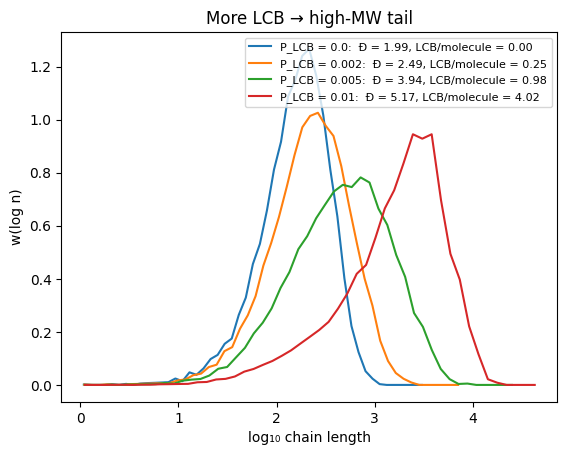

In [12]:
#@title Plot the MWDs
def wlog_hist(Dv, bins=50):
    edges = np.logspace(0, np.log10(3 * Dv.max()), bins)
    h, _ = np.histogram(Dv, bins=edges, weights=Dv)
    x = np.log10(np.sqrt(edges[1:]*edges[:-1])); y = h / np.diff(np.log10(edges))
    return x, y / np.trapezoid(y, x)
for P_LCB, (Dv, Bv) in mwd_runs.items():
    PDI = (Dv**2).sum() / Dv.sum() / Dv.mean()
    x, y = wlog_hist(Dv)
    plt.plot(x, y, label=f"P_LCB = {P_LCB}:  Đ = {PDI:.2f}, LCB/molecule = {Bv.mean():.2f}")
plt.xlabel("log₁₀ chain length"); plt.ylabel("w(log n)"); plt.legend(fontsize=8); plt.title("More LCB → high-MW tail"); plt.show()

## 6 · Who carries the branches?
Long molecules are where the branches live, and where the hyperbranched ones appear.

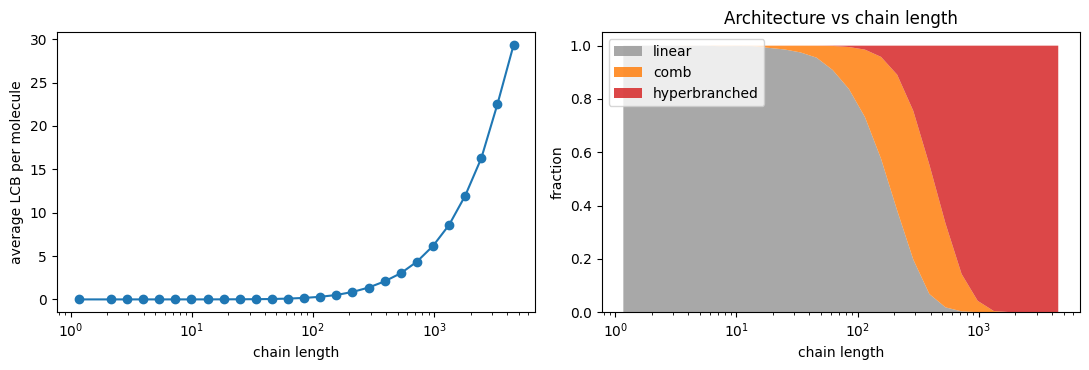

In [13]:
#@title Plot branches and architecture against chain length
edges = np.logspace(0, np.log10(D.max() + 1), 30); mid = np.sqrt(edges[1:] * edges[:-1]); which = np.digitize(D, edges) - 1
avgB, lin, cmb, hyp, mids = [], [], [], [], []
for b in range(len(mid)):
    s = which == b
    if s.sum() < 20: continue
    mids.append(mid[b]); avgB.append(B[s].mean()); lin.append(np.mean(B[s] == 0))
    cmb.append(np.mean((B[s] > 0) & (HB[s] == 0))); hyp.append(np.mean(HB[s] > 0))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(mids, avgB, "o-"); ax[0].set_xlabel("chain length"); ax[0].set_ylabel("average LCB per molecule")
ax[1].stackplot(mids, lin, cmb, hyp, labels=["linear", "comb", "hyperbranched"], colors=["#999", "tab:orange", "tab:red"], alpha=0.85)
ax[1].set_xscale("log"); ax[1].set_xlabel("chain length"); ax[1].set_ylabel("fraction"); ax[1].legend(loc="upper left"); ax[1].set_title("Architecture vs chain length")
plt.tight_layout(); plt.show()

## ✅ Recap
- A **pool** (a plain list) lets molecules made *earlier* react *later*.
- Fast random removal: copy the last element into the gap, then `pop()`.
- Each molecule carries extra labels (branches, branch-on-branch), so its architecture comes for free.

### 🧪 Try it yourself
1. Set `P_CTA = 1.0` (no β-hydride elimination). What happens to the branching? Why?
2. Which affects Đ more: doubling `P_LCB`, or halving `P_CTA`?
3. Plot how many molecules have 0, 1, 2, … branches (hint: `np.bincount(B)`).

➡️ **Next: Notebook 5 — Step growth & gelation**